# 02 · Leakage-safe features and baselines

A forecasting model is only as honest as its features. This notebook builds every feature from the **strict past**, proves that it does, tunes the rating system on validation data, and fits the classical baselines the neural network must beat.

## Feature engineering

For each match we compute, from results of *earlier match days only*:

| feature | meaning |
|---|---|
| `elo_h`, `elo_a`, `elo_diff` | Elo-style rating of both clubs. Updated after each match with a goal-difference multiplier; new clubs start from a shrunk average of their country's clubs, so a debutant from England is not treated like one from Luxembourg; ratings regress slightly towards the mean between seasons |
| `form_pts_*`, `form_gd_*` | exponentially weighted points and goal difference over the last 5 matches, shrunk towards the league average when a club has few matches |
| `att_*`, `dfn_*` | smoothed goals scored / conceded over the last 10 matches |
| `log_n_*` | log of the number of Champions League matches played so far (experience) |
| `neutral`, `is_knockout`, `is_second_leg`, `is_final` | venue and stage context known before kick-off (finals and the 2020 Lisbon "bubble" are neutral) |

**The one rule that prevents leakage:** on each match day, features of *all* that day's matches are read from the rating state first; only then are that day's results fed into it. A match can therefore never influence its own features or those of a same-day match. The same `RatingState` object serves training, prediction and simulation, so there is no train/serve skew.

In [1]:
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

from ucl import experiments as X
from ucl import plotting as P
from ucl.data import load_matches
from ucl.features import FEATURES_ALL, EloParams, build_features

P.apply_style()
pd.set_option("display.width", 140)
T0 = time.perf_counter()
matches = load_matches()

### Proof of no leakage

The pytest suite (`tests/test_leakage.py`) checks this property on synthetic and real data; here is the same experiment live. We **replace every result from 1 September 2021 onwards with random scores**, rebuild all features, and compare. If any feature peeked at the future, rows before the cutoff would change.

In [2]:
cutoff = pd.Timestamp("2021-09-01")
rng = np.random.default_rng(0)
corrupted = matches.copy()
future = corrupted.date >= cutoff
corrupted.loc[future, "home_goals"] = rng.integers(0, 6, future.sum())
corrupted.loc[future, "away_goals"] = rng.integers(0, 6, future.sum())

f_true, _ = build_features(matches, EloParams())
f_corr, _ = build_features(corrupted, EloParams())
cols = [
    c
    for c in f_true.columns
    if c
    not in {
        "match_id",
        "season",
        "date",
        "stage",
        "round",
        "home",
        "away",
        "home_country",
        "away_country",
        "y",
        "goal_diff",
    }
]
past, later = f_true.date <= cutoff, f_true.date > cutoff
diff_past = (f_true.loc[past, cols] - f_corr.loc[past, cols]).abs().to_numpy().max()
diff_later = (f_true.loc[later, cols] - f_corr.loc[later, cols]).abs().to_numpy().max()
display(
    Markdown(
        f"* max |feature difference| over the **{past.sum():,} matches up to the cutoff**: **{diff_past:.1f}** (must be exactly 0)\n"
        f"* same quantity over the {later.sum()} matches after it: {diff_later:.1f} — so features *do* react to past results, the test has power."
    )
)
assert diff_past == 0.0 and diff_later > 0

* max |feature difference| over the **3,374 matches up to the cutoff**: **0.0** (must be exactly 0)
* same quantity over the 753 matches after it: 312.2 — so features *do* react to past results, the test has power.

## Choosing the rating hyper-parameters (validation only)

Elo has a few knobs: the update size `k`, the home bonus used in the update, between-season regression, and how strongly a debutant is anchored to its country's average. We grid-search them by the validation log-loss of the simplest downstream model (logistic regression on `elo_diff` and the neutral flag). Training data fits the classifier; the validation seasons choose the knobs; the test seasons are not used.

In [3]:
t = time.perf_counter()
best, grid = X.select_elo_params(matches)
X.save_json(
    {"best": best.__dict__, "grid_size": len(grid), "best_val_log_loss": float(grid.val_log_loss.iloc[0])},
    "elo_params.json",
)
display(Markdown(f"{len(grid)} configurations in {time.perf_counter() - t:.0f}s. Best: `{best}`."))
grid.head(6).round(4)

60 configurations in 40s. Best: `EloParams(k=15.0, home_advantage=60.0, season_regression=0.0, country_prior_weight=0.5)`.

,k,home_advantage,season_regression,country_prior_weight,val_log_loss
0,15,60,0.0,0.5,0.9448
1,15,100,0.0,0.5,0.9449
2,10,60,0.0,0.5,0.9457
3,10,100,0.0,0.5,0.9461
4,25,100,0.0,0.5,0.9474
5,25,60,0.0,0.5,0.9475


In [4]:
display(
    Markdown(
        f"Validation log-loss ranges from **{grid.val_log_loss.min():.4f}** to **{grid.val_log_loss.max():.4f}** across the whole grid "
        f"(uniform guessing: {np.log(3):.4f}) — the result is insensitive to the knobs, which is reassuring: we are not squeezing noise out of the validation set. "
        f"A small-to-moderate `k` wins (no between-season regression is best, at the edge of the grid): with only ~12 Champions League matches per club-season, each result carries little information."
    )
)

Validation log-loss ranges from **0.9448** to **0.9783** across the whole grid (uniform guessing: 1.0986) — the result is insensitive to the knobs, which is reassuring: we are not squeezing noise out of the validation set. A small-to-moderate `k` wins (no between-season regression is best, at the edge of the grid): with only ~12 Champions League matches per club-season, each result carries little information.

In [5]:
ds = X.load_dataset()
tr, va, te = ds.train, ds.val, ds.test
display(
    Markdown(
        f"Features built in one chronological pass: train **{len(tr)}**, validation **{len(va)}**, test **{len(te)}** matches, **{len(FEATURES_ALL)}** model features."
    )
)
ds.feats[
    [
        "date",
        "home",
        "away",
        "elo_h",
        "elo_a",
        "form_pts_h",
        "form_pts_a",
        "log_n_h",
        "neutral",
        "is_knockout",
        "y",
    ]
].tail(5).round({"elo_h": 0, "elo_a": 0, "form_pts_h": 2, "form_pts_a": 2, "log_n_h": 2})

Features built in one chronological pass: train **2880**, validation **494**, test **753** matches, **17** model features.

,date,home,away,elo_h,elo_a,form_pts_h,form_pts_a,log_n_h,neutral,is_knockout,y
4122,2026-04-28,paris saint germain|FRA,bayern munchen|GER,1806.0,1864.0,2.23,2.38,5.20,0.0,1.0,0
4123,2026-04-29,atletico madrid|ESP,arsenal|ENG,1673.0,1769.0,1.47,1.82,5.02,0.0,1.0,1
4124,2026-05-05,arsenal|ENG,atletico madrid|ESP,1769.0,1673.0,1.56,1.28,5.37,0.0,1.0,0
4125,2026-05-06,bayern munchen|GER,paris saint germain|FRA,1856.0,1813.0,1.82,2.38,5.77,0.0,1.0,1
4126,2026-05-30,paris saint germain|FRA,arsenal|ENG,1815.0,1773.0,2.01,1.85,5.21,1.0,1.0,1


### Do the ratings track reality?

A sanity check on the feature that matters most. Pre-match Elo (before each match, so no leakage) for a few dominant clubs: Real Madrid's 2010s run, Bayern's 2010s and 2020 peak, Manchester City's rise, and Barcelona's decline are all visible even though the system sees nothing but Champions League results.

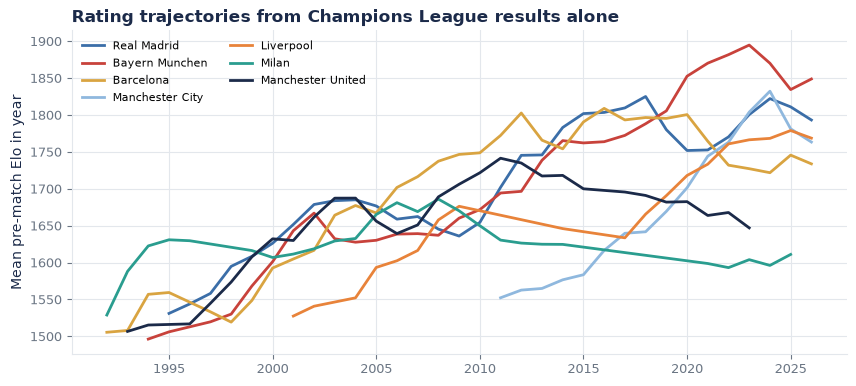

In [6]:
f = ds.feats
long = pd.concat(
    [
        f[["date", "home", "elo_h"]].set_axis(["date", "team", "elo"], axis=1),
        f[["date", "away", "elo_a"]].set_axis(["date", "team", "elo"], axis=1),
    ]
).sort_values("date")
show = {
    "real madrid|ESP": "blue",
    "bayern munchen|GER": "red",
    "barcelona|ESP": "gold",
    "manchester city|ENG": "sky",
    "liverpool|ENG": "orange",
    "milan|ITA": "teal",
    "manchester united|ENG": "navy",
}
fig, ax = plt.subplots(figsize=(10, 4.2))
for team, col in show.items():
    s = long[long.team == team]
    s = s.groupby(s.date.dt.year).elo.mean()
    ax.plot(s.index, s.values, color=P.COLORS[col], lw=2, label=P.pretty_team(team))
ax.set_ylabel("Mean pre-match Elo in year")
ax.set_title("Rating trajectories from Champions League results alone")
ax.legend(ncol=2, fontsize=8, loc="upper left")
P.save(fig, "elo_trajectories")
plt.show()

### Is there signal? Upsets versus the rating gap

If Elo is informative, home wins should become more common, and upsets rarer, as the home side's rating advantage grows. We use training matches at non-neutral venues.

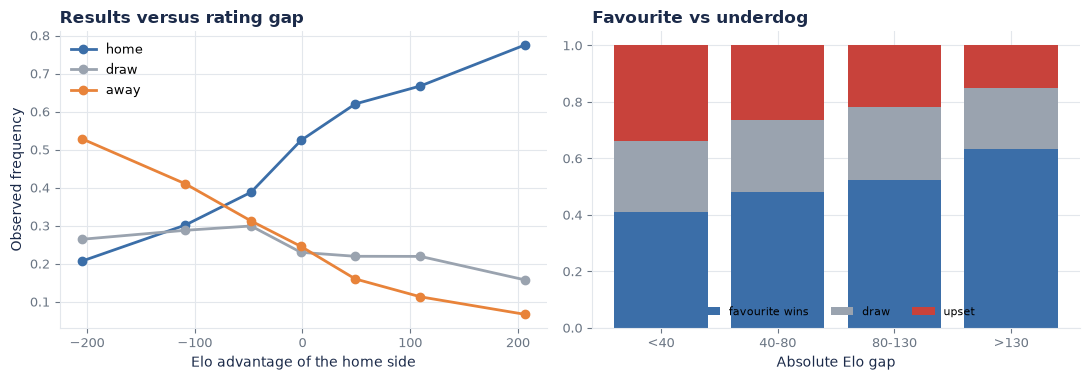

Upsets happen in **34%** of near-equal pairings and in **15%** of the most lopsided ones: football stays noisy, which caps what any model can achieve.

In [7]:
d = tr[tr.neutral == 0].copy()
d["bin"] = pd.cut(d.elo_diff, [-400, -150, -75, -25, 25, 75, 150, 400])
freq = (
    d.groupby("bin", observed=True)
    .y.value_counts(normalize=True)
    .unstack()
    .rename(columns={0: "home", 1: "draw", 2: "away"})
)
mid = d.groupby("bin", observed=True).elo_diff.mean()

fav = d.assign(gap=d.elo_diff.abs(), fav_home=d.elo_diff > 0)
fav["fav_result"] = np.where(
    fav.fav_home,
    fav.y.map({0: "favourite wins", 1: "draw", 2: "upset"}),
    fav.y.map({2: "favourite wins", 1: "draw", 0: "upset"}),
)
fav["gap_bin"] = pd.cut(fav.gap, [0, 40, 80, 130, 400], labels=["<40", "40-80", "80-130", ">130"])
share = (
    fav.groupby("gap_bin", observed=True)
    .fav_result.value_counts(normalize=True)
    .unstack()[["favourite wins", "draw", "upset"]]
)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.9))
for k in ["home", "draw", "away"]:
    axes[0].plot(mid.values, freq[k].values, "o-", color=P.OUTCOME_COLORS[k], label=k, lw=2)
axes[0].set_xlabel("Elo advantage of the home side")
axes[0].set_ylabel("Observed frequency")
axes[0].legend()
axes[0].set_title("Results versus rating gap")
bottom = np.zeros(len(share))
for k, c in zip(share.columns, [P.COLORS["blue"], P.COLORS["grey"], P.COLORS["red"]], strict=False):
    axes[1].bar(share.index.astype(str), share[k], bottom=bottom, color=c, label=k)
    bottom += share[k].to_numpy()
axes[1].set_xlabel("Absolute Elo gap")
axes[1].set_title("Favourite vs underdog")
axes[1].legend(fontsize=8, ncol=3, loc="lower center")
fig.tight_layout()
P.save(fig, "elo_signal")
plt.show()
display(
    Markdown(
        f"Upsets happen in **{share.loc['<40', 'upset']:.0%}** of near-equal pairings and in **{share.loc['>130', 'upset']:.0%}** of the most lopsided ones: football stays noisy, which caps what any model can achieve."
    )
)

## Baselines

Four reference models, all sharing the data and splits of the deep model:

1. **Uniform** — 1/3 each. The "knows nothing" reference.
2. **Base rates** — training-set home / draw / away frequencies. Captures home advantage, nothing else.
3. **Elo + logistic regression** — multinomial logistic regression on `elo_diff` and the neutral flag. The standard strong, interpretable baseline.
4. **All features + logistic regression** and **gradient boosting** — the same features the neural network sees, with a tuned linear and a tuned tree model. These are the baselines that make the comparison *fair*: if the network wins, it should be because of the architecture, not because it saw more information.

Hyper-parameters of both are chosen on validation log-loss (grids below), with an effort comparable to the network's random search.

In [8]:
t = time.perf_counter()
C_best, lr_tab = X.tune_logreg(tr, va)
gbm_best, gbm_tab = X.tune_gbm(tr, va)
hp = {"logreg_C": C_best, "gbm": gbm_best}
X.save_json(hp, "baseline_hparams.json")
display(
    Markdown(
        f"Tuned in {time.perf_counter() - t:.0f}s. Logistic regression C = **{C_best}**; gradient boosting = `{gbm_best}`."
    )
)
display(lr_tab.head(3).round(4))
display(gbm_tab.head(3).round(4))

Tuned in 11s. Logistic regression C = **0.01**; gradient boosting = `{'max_depth': 2, 'max_iter': 50, 'min_samples_leaf': 20, 'l2': 1.0, 'learning_rate': 0.05}`.

,C,val_log_loss
0,0.010,0.9534
1,0.003,0.9536
2,0.030,0.9544


,max_depth,max_iter,min_samples_leaf,l2,learning_rate,val_log_loss
0,2,50,20,1.0,0.05,0.9500
1,3,50,20,1.0,0.05,0.9524
2,2,100,20,1.0,0.05,0.9535


In [9]:
t = time.perf_counter()
models = X.fit_baselines(tr, va, hp)
fit_s = time.perf_counter() - t
val_tab = X.metrics_table(models, va)
test_tab = X.metrics_table(models, te)
out = pd.concat({"validation": val_tab, "test": test_tab}, axis=1)
display(
    Markdown(
        f"All baselines fitted in {fit_s:.1f}s. Lower is better except accuracy; ECE = class-wise expected calibration error."
    )
)
out.round(4)

All baselines fitted in 0.1s. Lower is better except accuracy; ECE = class-wise expected calibration error.

validation                                      test                                 
                                     log_loss   brier     rps accuracy     ece log_loss   brier     rps accuracy     ece
Uniform                                1.0986  0.6667  0.2440   0.4372  0.0000   1.0986  0.6667  0.2470   0.4887  0.0000
Base rates                             1.0789  0.6541  0.2455   0.4372  0.0409   1.0439  0.6288  0.2374   0.4887  0.0066
Elo + logistic regression              0.9448  0.5551  0.1974   0.5688  0.0245   0.9489  0.5552  0.2017   0.5684  0.0279
All features + logistic regression     0.9534  0.5609  0.1999   0.5587  0.0313   0.9349  0.5484  0.1979   0.5764  0.0249
Gradient boosting                      0.9500  0.5601  0.1996   0.5547  0.0177   0.9325  0.5474  0.1978   0.5870  0.0202

In [10]:
better = test_tab.loc["Elo + logistic regression", "log_loss"] < test_tab.loc["Base rates", "log_loss"]
display(
    Markdown(
        f"* Test log-loss: uniform **{test_tab.loc['Uniform', 'log_loss']:.4f}** → base rates **{test_tab.loc['Base rates', 'log_loss']:.4f}** → "
        f"Elo logistic regression **{test_tab.loc['Elo + logistic regression', 'log_loss']:.4f}**. Ratings from past results are clearly informative "
        f"(relative improvement over base rates: {1 - test_tab.loc['Elo + logistic regression', 'log_loss'] / test_tab.loc['Base rates', 'log_loss']:.1%}).\n"
        f"* Adding form, attack/defence and experience, or switching to boosted trees, moves test log-loss to "
        f"{test_tab.loc['All features + logistic regression', 'log_loss']:.4f} (linear) and {test_tab.loc['Gradient boosting', 'log_loss']:.4f} (trees), "
        f"i.e. gains of {test_tab.loc['Elo + logistic regression', 'log_loss'] - test_tab.loc['All features + logistic regression', 'log_loss']:.3f} / "
        f"{test_tab.loc['Elo + logistic regression', 'log_loss'] - test_tab.loc['Gradient boosting', 'log_loss']:.3f} that notebook 03 tests for significance "
        f"(on the validation seasons the ordering is the opposite: Elo-only is best), a first hint of how noisy a few hundred matches are.\n"
        f"* Accuracy tops out around {test_tab.accuracy.max():.0%} (the Uniform / Base-rate rows are 'always home'): football outcomes are intrinsically noisy."
    )
)
X.record_runtime("02_features_and_baselines", time.perf_counter() - T0)

* Test log-loss: uniform **1.0986** → base rates **1.0439** → Elo logistic regression **0.9489**. Ratings from past results are clearly informative (relative improvement over base rates: 9.1%).
* Adding form, attack/defence and experience, or switching to boosted trees, moves test log-loss to 0.9349 (linear) and 0.9325 (trees), i.e. gains of 0.014 / 0.016 that notebook 03 tests for significance (on the validation seasons the ordering is the opposite: Elo-only is best), a first hint of how noisy a few hundred matches are.
* Accuracy tops out around 59% (the Uniform / Base-rate rows are 'always home'): football outcomes are intrinsically noisy.

**Take-away.** Almost all of the predictable signal is in a club's long-run strength, and a one-parameter-family Elo system with a logistic link captures most of it. Extra hand-made features add little on ~2,900 training matches. That is the bar the neural network has to clear.